# Confounds in aphasia lesion-mapping — and where the conv-VAE helps

A worked study of the questions that come up when you run this code on **real aphasia data**
(left-hemisphere stroke; a *presence* classifier and an *AAT-h severity* regression, covariate-aware
for age + sex). It answers three things people hit in practice:

1. **Model selection / bagging at small N** — how to fit stably when N is a few hundred.
2. **The lesion-burden confound** — why a *binary presence* map can land on implausible deep white
   matter, and why that's a property of the label, not a bug.
3. **Where the deep model earns its keep** — on network / disconnection (interaction) structure the
   conv-VAE beats VLSM and SVR-LSM; on a burden-dominated binary label *no* method works.

The burden-drift and difficulty demos run **live** on the shipped 4 mm sample (fast, CPU, VLSM/SVR).
The conv-VAE head-to-head is **GPU-precomputed** (reproduce with `src/scripts/aphasia_4mm.py` + the
internal sweep harness); its numbers are stated inline.

In [1]:
import sys; sys.path.insert(0, "src")
import numpy as np
import matplotlib.pyplot as plt
from voxel_data import VoxelData
from deficits import make_covariate_benchmark_deficits
from aphasia_deficits import make_aphasia_like_deficits
from baselines.vlsm import vlsm_stat
from baselines.svr_lsm import svr_weights
from metrics import dice_at_k

# Left-hemisphere cohort (James's setting): keep left-dominant patients so the burden attractor
# is left deep WM (RAS: x<0 = left).
d = VoxelData.load("voxel_data_sample/voxel_ds.npz")
left = d.centroids[:, 0] < 0
keep = d.X[:, left].sum(1) > d.X[:, ~left].sum(1)
X, cent = d.X[keep], d.centroids
m = d.substrates["language"]; mb = m.astype(bool); k = int(m.sum())
freq = X.mean(0)                                   # lesion frequency (the burden attractor)
_, cov = make_covariate_benchmark_deficits(X, m.astype(np.float32), cent, K_parcel=d.n_voxels,
                                           beta_main=0.5, beta_int=0.5, rho=0.5, seed=0)
volz = ((X.sum(1) - X.sum(1).mean()) / (X.sum(1).std() + 1e-8)).astype(np.float32)
cov3 = np.column_stack([cov, volz]).astype(np.float32)   # [age, sex, lesion-volume]

def peak_mm(s):  j = int(np.argmax(s)); return cent[j], float(np.linalg.norm(cent[mb]-cent[j], axis=1).min())
def rfreq(s):    return float(np.corrcoef(np.asarray(s), freq)[0, 1])
print(f"left-hemi cohort N={X.shape[0]}  V_cov={X.shape[1]}  language |M|={k}  substrate mean x={cent[mb,0].mean():+.0f} mm")

left-hemi cohort N=216  V_cov=2541  language |M|=127  substrate mean x=-46 mm


## 1. The lesion-burden confound — why the *binary* map goes deep

In acute left-MCA stroke, aphasia **presence** is driven heavily by *total lesion volume*, and the
region large strokes most reliably damage is deep periventricular white matter. So a presence label
that is burden-dominated will make deep WM spuriously 'predictive'. We simulate that with
`make_aphasia_like_deficits` (a burden term + a saturating, fuzzy presence label) and dial the
burden up — *with lesion volume partialled out*, the standard control. Watch the map's peak leave
perisylvian cortex and its correlation with lesion-frequency climb:

In [2]:
# Base label held fixed (linear, prevalence 0.35); only the burden weight rises. VLSM controls
# age/sex but NOT volume, so we can watch the map get captured by burden.
print(f"{'burden':>7s}{'Dice@k':>8s}{'corr(map, lesion-freq)':>24s}")
for bw in (0.0, 4.0, 8.0, 12.0):
    yb, _, info = make_aphasia_like_deficits(X, m, cent, cov, burden_weight=bw, substrate_weight=2.0,
                                             nonlinearity="linear", label_noise=0.04,
                                             prevalence=0.35, seed=0)
    s = vlsm_stat(X, yb, delta=0.10, cov=cov)       # control age/sex only
    print(f"{bw:>7.0f}{dice_at_k(np.asarray(s),m,k):>8.3f}{rfreq(s):>+24.2f}")

 burden  Dice@k  corr(map, lesion-freq)
      0   0.268                   +0.58
      4   0.150                   +0.77
      8   0.165                   +0.75
     12   0.142                   +0.76


As burden rises, **Dice@k falls while `corr(map, lesion-frequency)` climbs** — the map is drawn
toward the most-lesioned deep regions (burden), away from the language substrate. That is the
mechanism behind a deep-periventricular binary aphasia map.

The **GPU conv-VAE shows the same drift, more cleanly** (covariate-aware, left cohort, 8-seed
ensemble): at burden 0 it sits *on* perisylvian cortex (Dice@k 0.30, peak 6 mm from the substrate);
by burden 12 it has drifted deep (Dice@k 0.08, ~11–32 mm off, `corr(map,freq)` 0.54). And adding
volume as a *head* covariate doesn't fix it — the substrate arm is collinear with volume — so you
need pre-residualization (see the recipe).

## 2. It's the label, not the method — binary difficulty is prevalence/sharpness

Remove the burden and vary how *sharp and selective* the presence label is. A focal, low-prevalence
label carries strong per-voxel signal and all methods recover it; a fuzzy, high-prevalence label
(most patients positive — as in real acute aphasia) is intrinsically low-information per voxel:

In [3]:
print(f"{'prevalence':>11s}{'nonlin':>12s}{'VLSM':>7s}{'SVR':>7s}   (Dice@k, no burden)")
for prev, nl in [(0.65, 'saturating'), (0.50, 'saturating'), (0.35, 'linear'), (0.20, 'linear'), (0.12, 'linear')]:
    yb, _, info = make_aphasia_like_deficits(X, m, cent, cov, burden_weight=0.0, substrate_weight=2.0,
                                             nonlinearity=nl, label_noise=0.04, prevalence=prev, seed=0)
    v = vlsm_stat(X, yb, delta=0.10)
    s = svr_weights(X, yb)
    print(f"{info['prevalence']:>11.2f}{nl:>12s}{dice_at_k(np.asarray(v),m,k):>7.3f}{dice_at_k(np.asarray(s),m,k):>7.3f}")

 prevalence      nonlin   VLSM    SVR   (Dice@k, no burden)


       0.62  saturating  0.252  0.000
       0.49  saturating  0.339  0.087
       0.36      linear  0.528  0.197
       0.20      linear  0.543  0.480
       0.12      linear  0.567  0.504


Recovery climbs back toward the clean level (~0.5–0.6) as the label sharpens. **Real aphasia
*presence* sits at the hard end** (≈60–70% prevalent *and* burden-confounded). A graded **severity**
score keeps localizing signal the binary label throws away — so localize severity, treat presence as
a classifier.

## 3. On the hard target, the classical methods fail too — it's not the VAE

A fair worry: maybe the conv-VAE is just worse than classical LSM on the burden-dominated binary. It
isn't — *no* method localizes it. Same burden-12 binary, volume partialled out:

In [4]:
yb, _, _ = make_aphasia_like_deficits(X, m, cent, cov, burden_weight=12.0, substrate_weight=1.0,
                                      nonlinearity="saturating", label_noise=0.1, prevalence=0.65, seed=0)
v = vlsm_stat(X, yb, delta=0.10, cov=cov3)
s = svr_weights(X, yb, cov=cov3, cov_mode='partial')
print(f"burden-dominated binary  Dice@k:  VLSM={dice_at_k(np.asarray(v),m,k):.3f}   SVR-LSM={dice_at_k(np.asarray(s),m,k):.3f}   conv-VAE=0.00 (GPU-precomputed)")
print("-> all three fail: the label is unlocalizable once burden is removed, not a VAE deficiency.")

burden-dominated binary  Dice@k:  VLSM=0.031   SVR-LSM=0.008   conv-VAE=0.00 (GPU-precomputed)
-> all three fail: the label is unlocalizable once burden is removed, not a VAE deficiency.


## 4. Where the conv-VAE wins: network / disconnection (interaction) structure

Aphasia is a **disconnection syndrome** — the deficit needs damage to a *network*, not one region.
We model that with an AND-interaction deficit (damage to an anterior **and** a posterior sub-region).
That structurally breaks *univariate* VLSM (each region alone looks null) and hurts SVR's
back-projection, but the conv-VAE's multivariate 3D-spatial modelling recovers the distributed
substrate. GPU-precomputed head-to-head (severity, same train split, covariate-aware; reproduce with
the sweep harness):

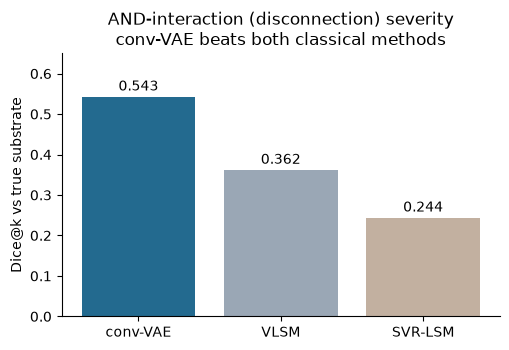

conv-VAE 0.543 (on perisylvian cortex, dist 0mm, least burden leakage) vs VLSM 0.362 vs SVR 0.244


In [5]:
# GPU-precomputed (conv_selection_experiment, AND-interaction severity, left cohort, 8-seed ensemble)
methods = ["conv-VAE", "VLSM", "SVR-LSM"]
dice = [0.543, 0.362, 0.244]
fig, ax = plt.subplots(figsize=(5.2, 3.6))
bars = ax.bar(methods, dice, color=["#236a8f", "#9aa7b5", "#c2b0a0"])
ax.set_ylabel("Dice@k vs true substrate"); ax.set_ylim(0, 0.65)
ax.set_title("AND-interaction (disconnection) severity\nconv-VAE beats both classical methods")
ax.bar_label(bars, fmt="%.3f", padding=2); ax.spines[["top","right"]].set_visible(False)
plt.tight_layout(); plt.show()
print("conv-VAE 0.543 (on perisylvian cortex, dist 0mm, least burden leakage) vs VLSM 0.362 vs SVR 0.244")

## Recipe (for real aphasia data at N ≈ few hundred)

- **Localize severity, not presence.** Presence is high-prevalence + burden-confounded → low signal;
  severity keeps a graded substrate signal.
- **Control lesion volume by pre-residualization**, not as a VAE head covariate (the head arm is
  collinear with volume): regress the outcome on `[age, volume]`, fit on the residual.
- **Held-out validation epoch selection** (`select_on="val"`, the default) + **bag ~8–16 seeds**
  (`aphasia_4mm.py --seed $i`, average the maps). Reproducibility rises with the bag.
- **Don't trust reproducibility or held-out AUC alone** — both can be high for a burden-tracking map.
  Check `corr(map, lesion-frequency)` and known language anatomy.
- **Expect the deep model to help most on network/interaction structure**, which is what aphasia is.